# Campus battery challenge: exploratory data analysis

**Challenge.** Write `BatteryAgent.act(obs)`: each hour it returns a power setpoint (kW) for a 2000 kWh / 500 kW campus battery (90% round trip, SOC starts at 50%, only 24 h of price and CO2 forecast). Score = 70% CO2 reduction + 30% cost reduction versus a no-battery baseline, minus penalties for physical infractions. The hidden test set is the last 7 days of every month.

**This notebook answers** what data we have and how far to trust it, how campus load and PV behave, how price and CO2 move through the day, and whether the daily price/CO2 swing is large enough to make cycling the battery worthwhile. The hourly analysis window is 2025-09-01 to 2026-08-31 (12 full months).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# One restrained palette used throughout
C_MAIN, C_ACC, C_GREY, C_LIGHT = "#1F4E79", "#E07B39", "#7F7F7F", "#D9D9D9"
CMAP_SEQ, CMAP_DIV = "viridis", "RdBu_r"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#E6E6E6", "grid.linewidth": 0.8, "axes.axisbelow": True,
})
pd.set_option("display.width", 150)
pd.set_option("display.max_columns", 30)


def find_root():
    # Works whether the kernel starts in the repo root or in notebooks/.
    for base in (Path.cwd(), Path.cwd().parent):
        if (base / "data" / "train").is_dir():
            return base
    raise FileNotFoundError(f"data/train not found from {Path.cwd()}")


ROOT = find_root()
DATA = ROOT / "data" / "train"
SPEC = json.loads((ROOT / "starter_kit" / "battery_spec.json").read_text(encoding="utf-8"))
FILES = {"precio": "precio_pvpc", "co2": "co2_red", "contador": "contador",
         "meteo": "meteo", "entradas": "entradas_salidas", "inversor": "inversor"}


def dr(start, end, freq):
    # Expected timestamp grid as datetime64[s], so it aligns with the loaded data.
    return pd.date_range(start, end, freq=freq).as_unit("s")


def load(key, keep=None):
    # Read a file indexed by 'Fecha'. keep = substrings (case-insensitive) selecting columns; None = all.
    usecols = None
    if keep is not None:
        usecols = lambda c: c == "Fecha" or any(k.upper() in c.upper() for k in keep)
    df = pd.read_csv(DATA / f"{FILES[key]}.csv", usecols=usecols, parse_dates=["Fecha"], index_col="Fecha")
    df.index = df.index.as_unit("s")
    return df.drop(columns=["Medida"], errors="ignore")


def find_col(df, *parts):
    # Locate exactly one column by case-insensitive substrings (avoids typing the long headers).
    hits = [c for c in df.columns if all(p.upper() in c.upper() for p in parts)]
    if len(hits) != 1:
        raise KeyError(f"{parts} matched {len(hits)} columns: {hits}")
    return hits[0]


def heat(ax, data, cmap, cbar_label, vmin=None, vmax=None):
    # imshow heatmap with a colour bar; returns the image.
    im = ax.imshow(data, aspect="auto", cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
    ax.grid(False)
    ax.figure.colorbar(im, ax=ax, label=cbar_label, pad=0.02)
    return im


def box_style(bp, color=C_MAIN):
    for box in bp["boxes"]:
        box.set(facecolor="#D6E4F0", edgecolor=color)
    for key in ("whiskers", "caps"):
        for line in bp[key]:
            line.set(color=color)
    for med in bp["medians"]:
        med.set(color=C_ACC, linewidth=2)
    for fl in bp["fliers"]:
        fl.set(marker=".", markersize=3, color=C_GREY, alpha=0.5)


print("root:", ROOT)
print("battery:", SPEC)

root: d:\Git\DatathonFME_UPCSostenibleChallenge
battery: {'capacity_kwh': 2000, 'power_kw': 500, 'efficiency': 0.9, 'soc_init': 0.5, 'soc_min': 0.0, 'soc_max': 1.0, 'dt_hours': 1, 'degradation': False}


## 1. The data at a glance

Six files. The four 5-minute files and the two hourly files share the same calendar, so every dataset is checked against one expected timestamp grid (2025-09-01 to 2026-09-01). The table counts what is actually present.

In [2]:
# Expected grids. 5-min stamps are read as interval ends (they start at 00:05).
GRID_5MIN = dr("2025-09-01 00:05", "2026-09-01 00:00", "5min")
GRID_HOUR = dr("2025-09-01 00:00", "2026-09-01 23:00", "h")
ANALYSIS_HOURS = dr("2025-09-01 00:00", "2026-08-31 23:00", "h")  # 12 full months, used from section 3 on

CATALOG = [  # key, label, expected grid, native frequency
    ("precio", "PVPC price", GRID_HOUR, "1 h"),
    ("co2", "CO2 intensity", GRID_HOUR, "1 h"),
    ("contador", "Campus meter", GRID_5MIN, "5 min"),
    ("meteo", "Weather station", GRID_5MIN, "5 min"),
    ("entradas", "I/O relay", GRID_5MIN, "5 min"),
    ("inversor", "Inverters", GRID_5MIN, "5 min"),
]


def timestamps(key):
    raw = pd.read_csv(DATA / f"{FILES[key]}.csv", usecols=["Fecha"], parse_dates=["Fecha"])
    return pd.DatetimeIndex(raw["Fecha"]).as_unit("s")


def n_data_cols(key):
    header = pd.read_csv(DATA / f"{FILES[key]}.csv", nrows=0).columns
    return sum(c not in ("Fecha", "Medida") for c in header)


IDX, rows = {}, []
for key, label, grid, freq in CATALOG:
    IDX[key] = timestamps(key)
    rows.append({
        "dataset": label, "rows": len(IDX[key]), "columns": n_data_cols(key), "frequency": freq,
        "start": IDX[key].min().strftime("%Y-%m-%d %H:%M"), "end": IDX[key].max().strftime("%Y-%m-%d %H:%M"),
        "% expected present": round(100 * grid.isin(IDX[key]).mean(), 1),
    })
overview = pd.DataFrame(rows).set_index("dataset")
overview

,rows,columns,frequency,start,end,% expected present
dataset,,,,,,
PVPC price,6768,2,1 h,2025-09-01 00:00,2026-09-01 23:00,77.0
CO2 intensity,6768,4,1 h,2025-09-01 00:00,2026-09-01 23:00,77.0
Campus meter,74210,27,5 min,2025-09-01 00:05,2026-09-01 00:00,70.6
Weather station,74210,18,5 min,2025-09-01 00:05,2026-09-01 00:00,70.6
I/O relay,74210,18,5 min,2025-09-01 00:05,2026-09-01 00:00,70.6
Inverters,71882,174,5 min,2025-09-01 00:05,2026-08-16 22:00,68.4


Text(0.5, 1.0, 'Daily coverage (white = no data)')

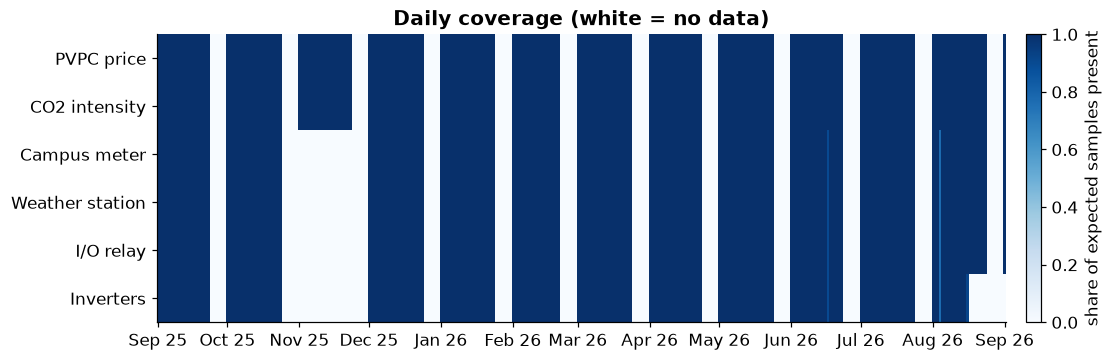

In [3]:
def daily_share(idx, grid):
    # Share of expected samples present, per calendar day.
    have = pd.Series(grid.isin(idx), index=grid)
    per_day = have.resample("D").agg(["sum", "count"])
    return per_day["sum"] / per_day["count"]


cov = pd.DataFrame({label: daily_share(IDX[key], grid) for key, label, grid, _ in CATALOG}).T
fig, ax = plt.subplots(figsize=(12, 3.4))
heat(ax, cov.to_numpy(), "Blues", "share of expected samples present", vmin=0, vmax=1)
ax.set_yticks(range(len(cov)), labels=cov.index)
month_ticks = [i for i, d in enumerate(cov.columns) if d.day == 1]
ax.set_xticks(month_ticks, labels=[cov.columns[i].strftime("%b %y") for i in month_ticks])
ax.set_title("Daily coverage (white = no data)")

In [4]:
# Outages: stretches with no meter timestamps that are longer than 15 min but shorter than 2 days
# (the monthly 7-day gaps and the November gap are longer and are excluded here)
idx5 = IDX["contador"]
gap = pd.Series(idx5[1:] - idx5[:-1], index=idx5[:-1])
outages = gap[(gap > pd.Timedelta("15min")) & (gap < pd.Timedelta("2D"))]
print("Outage stretches (last sample before the gap, gap length):")
print(pd.DataFrame({"last sample before gap": outages.index, "gap length": outages.to_numpy()}).to_string(index=False))

Outage stretches (last sample before the gap, gap length):
last sample before gap      gap length
   2026-06-17 14:55:00 0 days 02:30:00
   2026-08-04 07:05:00 0 days 05:35:00


**Takeaways**
- Every file lacks the last 7 days of each month, which are the hidden test windows. The hourly price and CO2 files are 77.0% complete; the 5-min files are 70.6% complete.
- November 2025 is blank in the four 5-min files, while price and CO2 cover it. There is no hourly load or PV for November.
- The inverter file ends on 2026-08-16 22:00 (68.4% complete overall), so PV is unobserved for the last two weeks.
- The two outages in the table above (from 2026-06-17 14:55, a 2 h 30 min gap; and from 2026-08-04 07:05, a 5 h 35 min gap) are too short to see at daily resolution. They show up as missing hours in section 3.

## 2. Column quality

Every column of every file is classed as *fully null*, *constant* (one distinct value) or *informative*. The timestamp and the `Medida` counter are excluded.

                 informative  constant  fully null
PVPC price                 2         0           0
CO2 intensity              4         0           0
Campus meter              22         4           1
Weather station           14         3           1
I/O relay                  9         0           9
Inverters                156        18           0


Text(0.5, 1.0, 'Column quality by dataset')

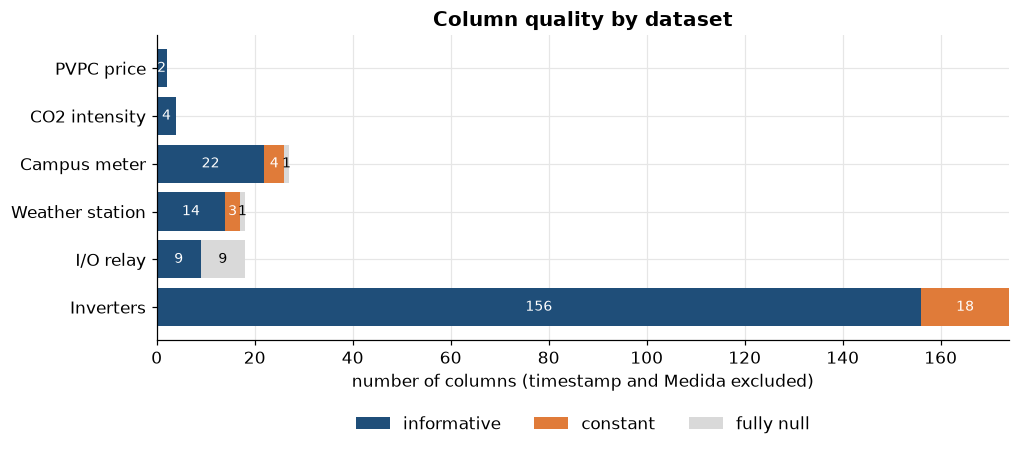

In [5]:
def column_quality(df):
    nonnull = df.notna().sum()
    distinct = df.nunique(dropna=True)
    return pd.Series(np.select([nonnull == 0, distinct <= 1], ["fully null", "constant"], "informative"),
                     index=df.columns)


DS_LABEL = {"precio": "PVPC price", "co2": "CO2 intensity", "contador": "Campus meter",
            "meteo": "Weather station", "entradas": "I/O relay", "inversor": "Inverters"}
CATS = ["informative", "constant", "fully null"]

full = {key: load(key) for key in FILES}  # full read: the quality audit needs every column
quality = (pd.DataFrame({k: column_quality(df).value_counts() for k, df in full.items()})
           .T.reindex(columns=CATS).fillna(0).astype(int))
quality.index = [DS_LABEL[k] for k in quality.index]
print(quality.to_string())

fig, ax = plt.subplots(figsize=(10, 3.6))
left = np.zeros(len(quality))
colors = {"informative": C_MAIN, "constant": C_ACC, "fully null": C_LIGHT}
for cat in CATS:
    vals = quality[cat].to_numpy()
    ax.barh(quality.index, vals, left=left, color=colors[cat], label=cat)
    for y, (x0, v) in enumerate(zip(left, vals)):
        if v:
            ax.text(x0 + v / 2, y, str(v), ha="center", va="center", fontsize=9,
                    color="black" if cat == "fully null" else "white")
    left = left + vals
ax.invert_yaxis()
ax.set_xlabel("number of columns (timestamp and Medida excluded)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
ax.set_title("Column quality by dataset")

In [6]:
# Constant columns, de-duplicated across the three inverters
for key, df in full.items():
    q = column_quality(df)
    const = sorted({c.split(" - ", 1)[-1] for c in q[q == "constant"].index})
    print(f"{DS_LABEL[key]} constant ({len(const)} distinct names): {const}")

# Oddities: scale, dead sensors, and whether 'energy' columns are cumulative registers
checks = [
    ("contador", find_col(full["contador"], "TENSI", "FASE 1")),
    ("contador", find_col(full["contador"], "CORRIENTE AC FASE 1")),
    ("contador", find_col(full["contador"], "ENERGIA ACTIVA IMPORTADA")),
    ("contador", find_col(full["contador"], "POTENCIA ACTIVA EXPORTADA")),
    ("inversor", find_col(full["inversor"], "Inversor 1", "TENSI", "FASE 1")),
    ("inversor", find_col(full["inversor"], "Inversor 1", "ENERGIA ACTIVA (kWh)")),
    ("meteo", find_col(full["meteo"], "VELOCIDAD VIENTO")),
    ("meteo", find_col(full["meteo"], "HORAS SOL PICO")),
    ("meteo", find_col(full["meteo"], "IRRADIANCIA (W/M2)")),
    ("entradas", "IoLogik 1214 - SALIDA RELE 0"),  # exact name: the '.1' duplicate also contains the text
]


def oddity(key, col):
    s = full[key][col].dropna()
    steps = s.diff().dropna()
    return {"dataset": key, "column": col.split(" - ", 1)[-1], "n": len(s), "median": s.median(),
            "min": s.min(), "max": s.max(), "share of steps down": (steps < 0).mean()}


oddities = pd.DataFrame([oddity(k, c) for k, c in checks]).set_index(["dataset", "column"])
oddities.round(3)

PVPC price constant (0 distinct names): []
CO2 intensity constant (0 distinct names): []
Campus meter constant (4 distinct names): ['ENERGIA ACTIVA EXPORTADA (kWh)', 'ENERGIA REACTIVA Q2 (kVArh)', 'ENERGIA REACTIVA Q3 (kVArh)', 'MODELO']
Weather station constant (3 distinct names): ['ATERSAMET ALARMA', 'MODELO', 'VELOCIDAD VIENTO (SENSOR 1) (m/s)']
I/O relay constant (0 distinct names): []
Inverters constant (6 distinct names): ['CORRIENTE AC FASE 1 (A)', 'CORRIENTE AC FASE 2 (A)', 'CORRIENTE AC FASE 3 (A)', 'MODELO', 'SETPOINT RELATIVO POTENCIA ACTIVA (%)', 'SETPOINT RELATIVO POTENCIA REACTIVA (%)']


n   median      min      max  share of steps down
dataset  column                                                                                  
contador TENSIÓN AC FASE 1-N (V)            74207    58.50     0.00    60.10                0.249
         CORRIENTE AC FASE 1 (A)            74207     1.20     0.00     3.30                0.155
         ENERGIA ACTIVA IMPORTADA (kWh)     74015    69.00     0.00  7643.00                0.299
         POTENCIA ACTIVA EXPORTADA (kW)     74207 -1058.00 -2696.00     0.00                0.333
inversor TENSIÓN AC FASE 1-N (V)            71879   229.79     0.00   240.43                0.270
         ENERGIA ACTIVA (kWh)               68483     0.05     0.00     5.03                0.265
meteo    VELOCIDAD VIENTO (SENSOR 1) (m/s)  74207     0.00     0.00     0.00                0.000
         HORAS SOL PICO (h)                 74208     0.00 -1367.73     0.11                0.139
         IRRADIANCIA (W/m2)                 74207     7.00     0.00  1326.00                0.266
entradas SALIDA RELE 0                      74207     1.00     0.00     1.00                0.000

In [7]:
pk = find_col(full["precio"], "PER_KWH")
pm = find_col(full["precio"], "PER_MWH")
print("Max |per_mwh/1000 - per_kwh| in the price file:", float((full["precio"][pm] / 1000 - full["precio"][pk]).abs().max()))
print("Relay signal values:", sorted(full["entradas"]["IoLogik 1214 - SALIDA RELE 0"].dropna().unique()))
print("Duplicate '.1' relay/meter columns, all null:",
      all(full["entradas"][c].isna().all() for c in full["entradas"].columns if c.endswith(".1")))

Max |per_mwh/1000 - per_kwh| in the price file: 9.974659986866641e-17
Relay signal values: [np.float64(0.0), np.float64(1.0)]
Duplicate '.1' relay/meter columns, all null: True


**Takeaways**
- Most columns carry information. Inverters have 156 informative, 18 constant and none fully null columns. The only fully null columns are the nine `.1` relay duplicates. The constant columns are `MODELO`, the three AC phase currents and the two setpoints.
- Columns worth using: meter `POTENCIA ACTIVA EXPORTADA (kW)` (load = minus this); the three inverter `POTENCIA ACTIVA (kW)` (PV = their sum); weather `IRRADIANCIA (W/m2)`, `TEMPERATURA AMBIENTE` and `TEMPERATURA PANEL`; price `precio_eur_per_kwh`; CO2 `co2_kg_per_kwh`. The relay `SALIDA RELE 0` is a 0/1 signal and is not used further.
- Oddities: meter voltage has a median of 58.5 V (the inverter voltage median is 229.8 V); meter current has a median of 1.2 A; wind speed is constant at 0; `HORAS SOL PICO` reaches -1368 h. The `ENERGIA` columns are per-interval, not cumulative: about 27-30% of steps go down.
- The meter reads exactly 0 kW in 197 samples. The runs of 6 or more are listed in section 3 (167 samples from 2026-06-17 17:25 to 06-18 07:15, and 22 on 2026-08-06). They are treated as missing.

## 3. Campus load

Campus load = minus the exported active power of the meter. PV = sum of the three inverters. Both are aggregated to hours with a shared function: an hour needs at least 6 of its 12 five-minute samples, otherwise it is left as a gap (NaN). Gaps stay on the grid, so the November hole stays visible.

In [8]:
def to_hourly(s, min_samples=6):
    # ASSUMPTION: 5-min stamps are interval ends, so the bin (h-1, h] is labelled h-1.
    g = s.resample("1h", closed="right", label="left")
    return g.mean().where(g.count() >= min_samples).reindex(ANALYSIS_HOURS)


ctr = load("contador", keep=["POTENCIA ACTIVA EXPORTADA"])
met = load("meteo", keep=["IRRADIANCIA (W/M2)", "TEMPERATURA"])
inv = load("inversor", keep=["POTENCIA ACTIVA (KW)"])  # only the three PV columns
del full["inversor"]  # the full 176-column frame is no longer needed

exp_col = find_col(ctr, "POTENCIA ACTIVA EXPORTADA")
print(f"Max exported power: {ctr[exp_col].max():.3f} kW (must be <= 0, so load = -export)")
# Exact 0 kW readings are outage artefacts (a campus never draws 0): treat them as missing
print(f"Exact-zero meter samples treated as missing: {int((ctr[exp_col] == 0).sum())}")
pv_cols = [find_col(inv, f"Inversor {i}", "POTENCIA ACTIVA (KW)") for i in (1, 2, 3)]

H = pd.DataFrame({
    "load_kw": to_hourly((-ctr[exp_col]).where(ctr[exp_col] != 0)),
    "pv_kw": to_hourly(inv[pv_cols].sum(axis=1, min_count=3)),
    "irr_w_m2": to_hourly(met[find_col(met, "IRRADIANCIA (W/M2)")]),
    "t_amb_c": to_hourly(met[find_col(met, "TEMPERATURA AMBIENTE")]),
    "t_panel_c": to_hourly(met[find_col(met, "TEMPERATURA PANEL")]),
    "price": full["precio"][pk].reindex(ANALYSIS_HOURS),
    "co2": full["co2"][find_col(full["co2"], "KG_PER_KWH")].reindex(ANALYSIS_HOURS),
}, index=ANALYSIS_HOURS)
H["net_load_kw"] = H.load_kw - H.pv_kw
H["hour"] = H.index.hour
H["dow"] = H.index.dayofweek
H["month"] = H.index.to_period("M")
H["weekend"] = H.dow >= 5
H["day_part"] = np.where(H.hour.between(7, 21), "day", "night")

print("Hours with data (of", len(H), "in the analysis window):")
print(H.notna().sum().to_string())
print("\nMean load (kW):", round(H.load_kw.mean(), 1), "| mean PV (kW):", round(H.pv_kw.mean(), 2))

Max exported power: 0.000 kW (must be <= 0, so load = -export)
Exact-zero meter samples treated as missing: 197
Hours with data (of 8760 in the analysis window):
load_kw        6169
pv_kw          5990
irr_w_m2       6184
t_amb_c        6184
t_panel_c      6184
price          6744
co2            6744
net_load_kw    5975
hour           8760
dow            8760
month          8760
weekend        8760
day_part       8760

Mean load (kW): 1118.1 | mean PV (kW): 26.51


In [9]:
# Exact-zero meter readings: runs of 6 or more consecutive stored samples (treated as missing above)
z = ctr[exp_col] == 0
run = (z != z.shift()).cumsum()
zr = pd.DataFrame({"start": z.index.to_series(), "z": z, "run": run})
zr = zr[zr.z].groupby("run").agg(start=("start", "min"), end=("start", "max"), samples=("z", "size"))
zero_runs = zr[zr.samples >= 6]
print(f"Exact-zero meter samples: {int(z.sum())}; runs of 6 or more: {len(zero_runs)}, "
      f"holding {int(zero_runs.samples.sum())} samples")
print(zero_runs.to_string())

Exact-zero meter samples: 197; runs of 6 or more: 2, holding 189 samples
                  start                 end  samples
run                                                 
6   2026-06-17 17:25:00 2026-06-18 07:15:00      167
10  2026-08-06 07:35:00 2026-08-06 09:20:00       22


Highest weekday-hour cell: Tue 12h at 1586 kW; lowest: Sun 13h at 688 kW


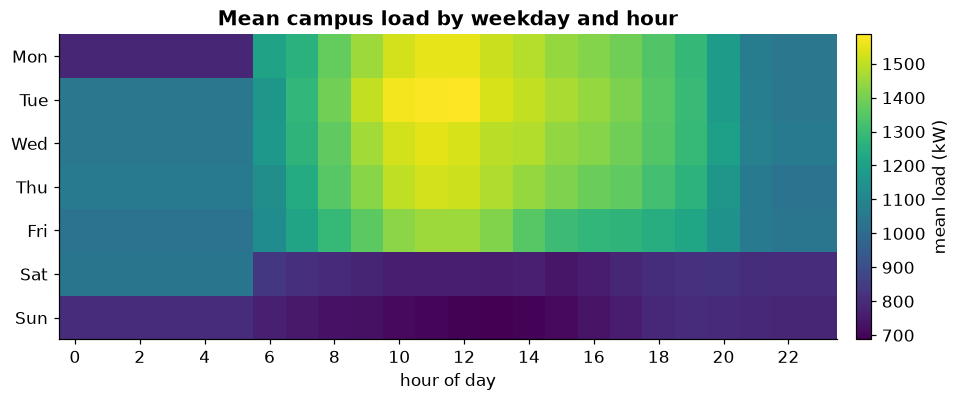

In [10]:
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
lh = H.pivot_table(index="dow", columns="hour", values="load_kw", aggfunc="mean")
fig, ax = plt.subplots(figsize=(11, 3.6))
heat(ax, lh.to_numpy(), CMAP_SEQ, "mean load (kW)")
ax.set_yticks(range(7), labels=DOW)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day")
ax.set_title("Mean campus load by weekday and hour")
st = lh.stack()
wd = lambda ij: f"{DOW[int(ij[0])]} {int(ij[1])}h"
print(f"Highest weekday-hour cell: {wd(st.idxmax())} at {st.max():.0f} kW; lowest: {wd(st.idxmin())} at {st.min():.0f} kW")

**Takeaways**
- Load is a weekday daytime plateau: the highest cell is Tue 12 h at 1586 kW, and the weekday 8-19 h block stays high.
- Weekends are flat and low from about 6 h onwards. The lowest cell is Sun 13 h at 688 kW.

           mean  median  count
month                         
2025-09  1154.0  1079.0    552
2025-10  1140.0  1073.0    576
2025-11     NaN     NaN      0
2025-12  1097.0  1058.0    576
2026-01  1083.0  1054.0    576
2026-02  1090.0  1100.0    504
2026-03  1082.0  1072.0    576
2026-04   999.0  1033.0    552
2026-05  1030.0  1051.0    576
2026-06  1325.0  1250.0    536
2026-07  1449.0  1287.0    576
2026-08   854.0   838.0    569


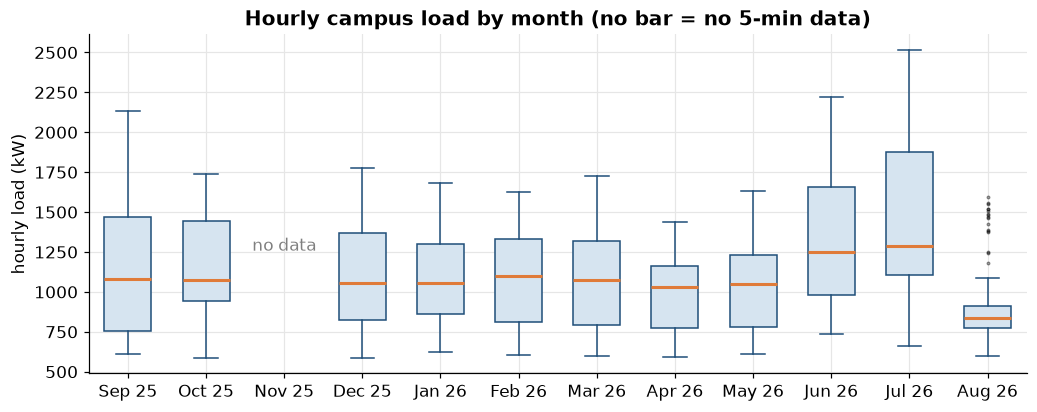

In [11]:
MONTHS = pd.period_range("2025-09", "2026-08", freq="M")
groups = [(i + 1, H.loc[H.month == m, "load_kw"].dropna()) for i, m in enumerate(MONTHS)]
present = [(pos, d) for pos, d in groups if len(d)]
fig, ax = plt.subplots(figsize=(11, 4))
box_style(ax.boxplot([d for _, d in present], positions=[p for p, _ in present], widths=0.6,
                     patch_artist=True, showfliers=True))
ax.set_xticks(range(1, 13), labels=[m.strftime("%b %y") for m in MONTHS])
ax.set_ylabel("hourly load (kW)")
ax.set_title("Hourly campus load by month (no bar = no 5-min data)")
nov_pos = [i + 1 for i, m in enumerate(MONTHS) if m == pd.Period("2025-11", "M")][0]
ax.text(nov_pos, np.nanmax(H.load_kw) * 0.5, "no data", ha="center", color=C_GREY)
print(H.groupby("month", observed=True)["load_kw"].agg(["mean", "median", "count"]).round(0).to_string())

**Takeaways**
- Load is seasonal. June and July are the highest months (means 1325 kW and 1449 kW; medians 1250 kW and 1287 kW), and April is among the lowest (mean 999 kW).
- August drops to a mean of 854 kW, well below July. The data does not say why; a campus shutdown in August is a likely cause and should be checked with the data owner.

{'weekday day': np.float64(1362.0), 'weekday night': np.float64(1042.0), 'weekend day': np.float64(756.0), 'weekend night': np.float64(822.0)}


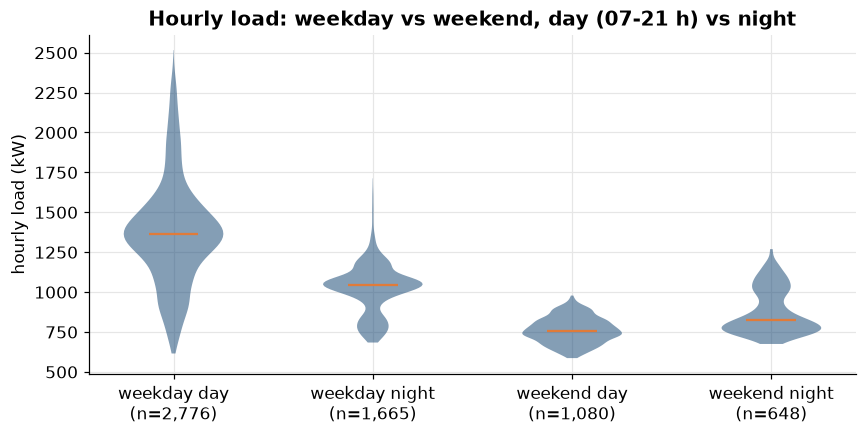

In [12]:
groups = {
    "weekday day": H.loc[~H.weekend & (H.day_part == "day"), "load_kw"].dropna(),
    "weekday night": H.loc[~H.weekend & (H.day_part == "night"), "load_kw"].dropna(),
    "weekend day": H.loc[H.weekend & (H.day_part == "day"), "load_kw"].dropna(),
    "weekend night": H.loc[H.weekend & (H.day_part == "night"), "load_kw"].dropna(),
}
fig, ax = plt.subplots(figsize=(9, 4))
parts = ax.violinplot(list(groups.values()), showmedians=True, showextrema=False)
for body in parts["bodies"]:
    body.set_facecolor(C_MAIN)
    body.set_alpha(0.55)
parts["cmedians"].set_color(C_ACC)
ax.set_xticks(range(1, 5), labels=[f"{k}\n(n={len(v):,})" for k, v in groups.items()])
ax.set_ylabel("hourly load (kW)")
ax.set_title("Hourly load: weekday vs weekend, day (07-21 h) vs night")
print({k: round(v.median(), 0) for k, v in groups.items()})

**Takeaways**
- Weekday daytime load has a median of 1362 kW, against 1042 kW at weekday night.
- Weekend load is much lower: 756 kW median by day and 822 kW by night. Weekend nights are higher than weekend days, so the daytime bulge is a weekday effect, likely occupancy-driven.

## 4. Solar

PV is compared with load on the same axes, so its small size is shown honestly.

PV hourly mean peaks at 89.7 kW at 12 h; load mean across hours is 1118 kW
Load profile: lowest hourly mean 971 kW at 0 h, highest 1308 kW at 11 h


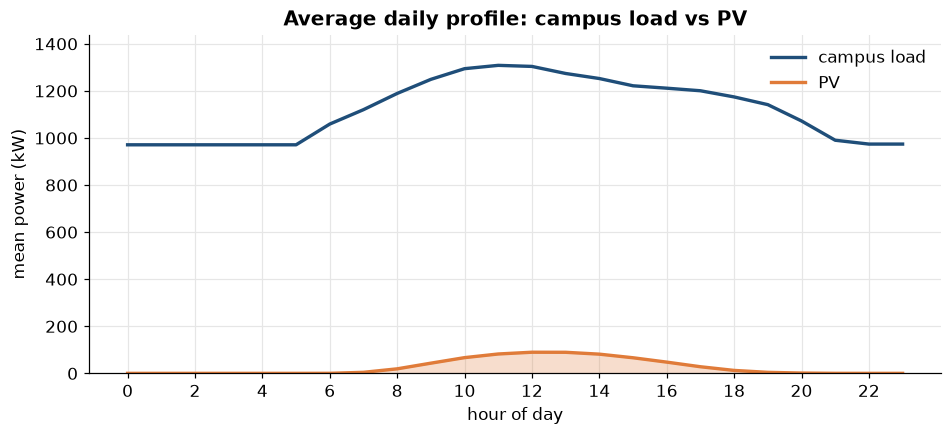

In [13]:
prof = H.groupby("hour")[["load_kw", "pv_kw"]].mean()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(prof.index, prof.load_kw, color=C_MAIN, lw=2.2, label="campus load")
ax.plot(prof.index, prof.pv_kw, color=C_ACC, lw=2.2, label="PV")
ax.fill_between(prof.index, 0, prof.pv_kw, color=C_ACC, alpha=0.25)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day")
ax.set_ylabel("mean power (kW)")
ax.set_ylim(0, prof.load_kw.max() * 1.1)
ax.legend(frameon=False)
ax.set_title("Average daily profile: campus load vs PV")
print(f"PV hourly mean peaks at {prof.pv_kw.max():.1f} kW at {prof.pv_kw.idxmax()} h; "
      f"load mean across hours is {prof.load_kw.mean():.0f} kW")
print(f"Load profile: lowest hourly mean {prof.load_kw.min():.0f} kW at {prof.load_kw.idxmin()} h, "
      f"highest {prof.load_kw.max():.0f} kW at {prof.load_kw.idxmax()} h")

**Takeaways**
- The average load runs from 971 kW at 0 h to a peak of 1308 kW at 11 h. PV peaks at 89.7 kW at 12 h, so at its peak it is less than 10% of load.
- PV is a thin midday hump next to a large base load. Its scale is far smaller than the load on this axis.

Hours with both: 5990; r = 0.997; irradiance min/max: 0 / 1062 W/m²
Net load (load - PV) < 0 in 0.00% of 5975 hours with both load and PV; min net load 460 kW
PV as share of load, mean over hours with both: 2.4%; peak PV 144 kW vs mean load 1118 kW


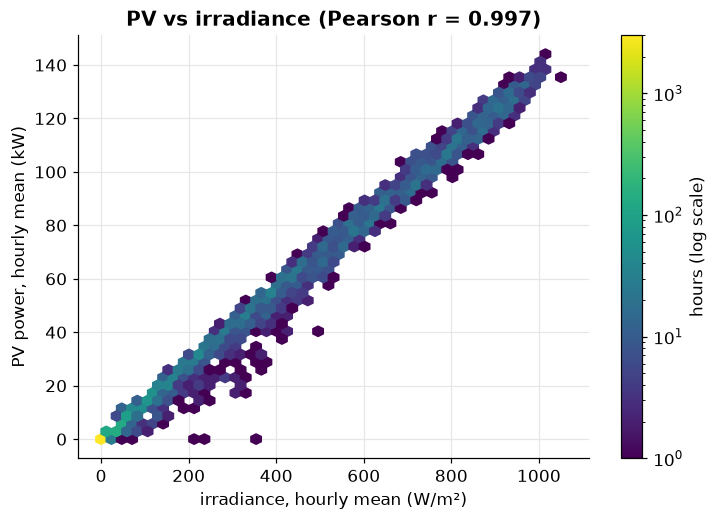

In [14]:
s = H[["irr_w_m2", "pv_kw"]].dropna()
r_pv_irr = s.irr_w_m2.corr(s.pv_kw)
fig, ax = plt.subplots(figsize=(7.5, 5))
hb = ax.hexbin(s.irr_w_m2, s.pv_kw, gridsize=45, cmap=CMAP_SEQ, mincnt=1, bins="log")
ax.figure.colorbar(hb, ax=ax, label="hours (log scale)")
ax.set_xlabel("irradiance, hourly mean (W/m²)")
ax.set_ylabel("PV power, hourly mean (kW)")
ax.set_title(f"PV vs irradiance (Pearson r = {r_pv_irr:.3f})")
print(f"Hours with both: {len(s)}; r = {r_pv_irr:.3f}; irradiance min/max: {s.irr_w_m2.min():.0f} / {s.irr_w_m2.max():.0f} W/m²")

net = H.net_load_kw.dropna()
print(f"Net load (load - PV) < 0 in {(net < 0).mean():.2%} of {len(net)} hours with both load and PV; "
      f"min net load {net.min():.0f} kW")
print(f"PV as share of load, mean over hours with both: {(H.pv_kw / H.load_kw).mean():.1%}; "
      f"peak PV {H.pv_kw.max():.0f} kW vs mean load {H.load_kw.mean():.0f} kW")

**Takeaways**
- Net load (load - PV) is never negative: 0.00% of 5975 hours with both values, and the lowest net load is 460 kW. There is no surplus solar to charge from, so any charging comes from the grid.
- PV follows irradiance almost exactly (r = 0.997). PV averages 2.4% of load (peak 144 kW against a mean load of 1118 kW), so a dedicated PV forecaster is not worth building.

## 5. Market signals

Hourly price (EUR/kWh) and CO2 intensity (kg/kWh) for the analysis window. The pricing day and the carbon signal are compared by hour and month, then correlated with the other hourly variables.

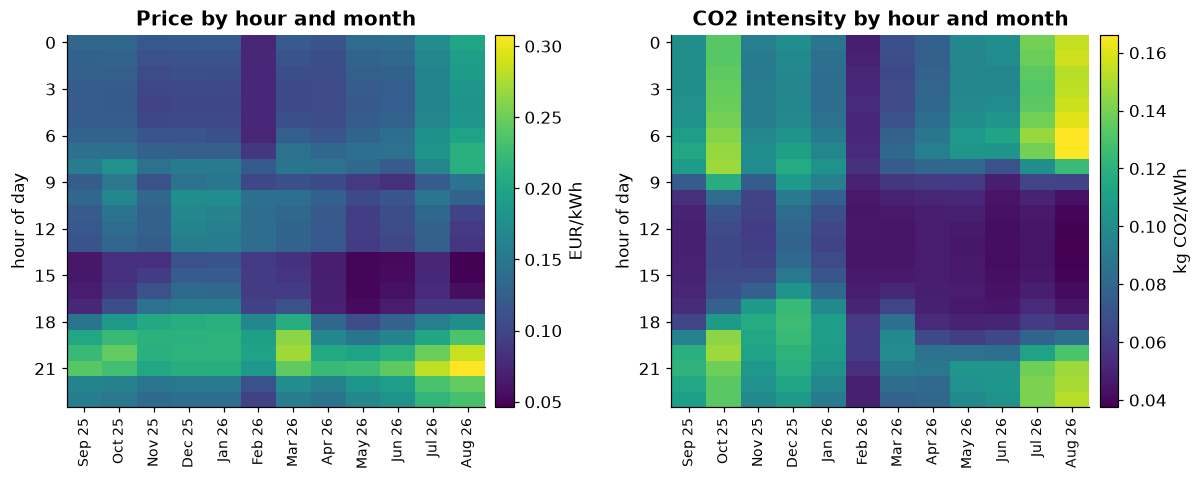

In [15]:
def by_hour_month(col):
    t_ = H.groupby(["hour", "month"], observed=True)[col].mean().unstack("month")
    t_.columns = [m.strftime("%b %y") for m in t_.columns]
    return t_


fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, (col, unit, title) in zip(axes, [("price", "EUR/kWh", "Price"), ("co2", "kg CO2/kWh", "CO2 intensity")]):
    t_ = by_hour_month(col)
    heat(ax, t_.to_numpy(), CMAP_SEQ, unit)
    ax.set_xticks(range(len(t_.columns)), labels=t_.columns)
    ax.tick_params(axis="x", labelrotation=90, labelsize=9)
    ax.set_yticks(range(0, 24, 3))
    ax.set_ylabel("hour of day")
    ax.set_title(f"{title} by hour and month")

**Takeaways**
- Price is lowest around 14-16 h and highest in the evening (18-23 h) in almost every month. August 2026 has the most expensive evenings (the brightest cells, near 0.30 EUR/kWh at 21 h).
- CO2 has its high band at night and in the early morning, and is lowest around midday. February 2026 appears to be the cleanest month at almost every hour.

Price mean: peak 0.234 EUR/kWh at 21 h, trough 0.076 at 14 h (ratio 3.07)
CO2 mean: peak 0.110 kg/kWh at 21 h, trough 0.052 at 13 h (ratio 2.11)


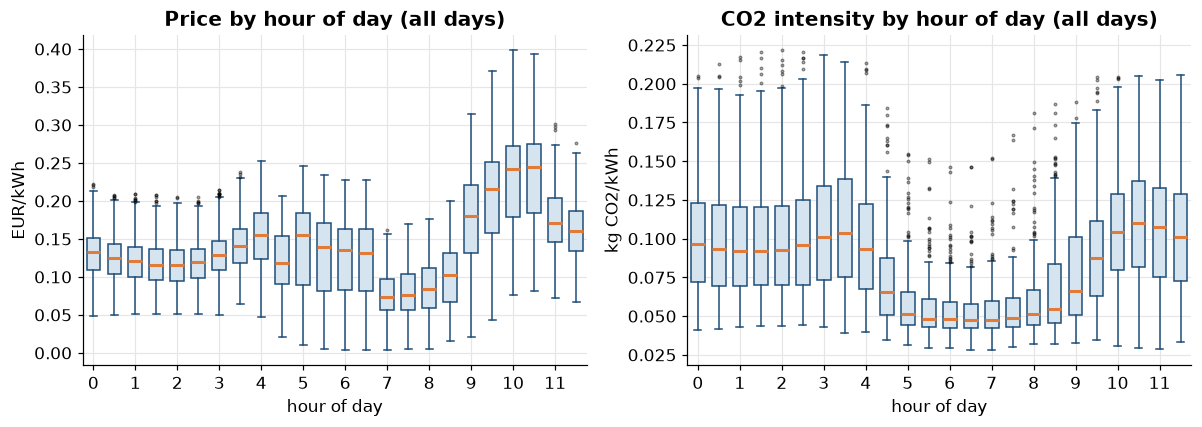

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9))
for ax, (col, unit, title) in zip(axes, [("price", "EUR/kWh", "Price"), ("co2", "kg CO2/kWh", "CO2 intensity")]):
    data = [H.loc[H.hour == h, col].dropna() for h in range(24)]
    box_style(ax.boxplot(data, positions=range(24), widths=0.65, patch_artist=True))
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlabel("hour of day")
    ax.set_ylabel(unit)
    ax.set_title(f"{title} by hour of day (all days)")
pm_ = H.groupby("hour").price.mean()
pc_ = H.groupby("hour").co2.mean()
print(f"Price mean: peak {pm_.max():.3f} EUR/kWh at {pm_.idxmax()} h, trough {pm_.min():.3f} at {pm_.idxmin()} h "
      f"(ratio {pm_.max() / pm_.min():.2f})")
print(f"CO2 mean: peak {pc_.max():.3f} kg/kWh at {pc_.idxmax()} h, trough {pc_.min():.3f} at {pc_.idxmin()} h "
      f"(ratio {pc_.max() / pc_.min():.2f})")

**Takeaways**
- Mean price peaks at 0.234 EUR/kWh at 21 h and bottoms out at 0.076 EUR/kWh at 14 h, a 3.07x spread.
- Mean CO2 peaks at 0.110 kg/kWh at 21 h and bottoms out at 0.052 kg/kWh at 13 h, a 2.11x spread. Both signals call for charging around midday and discharging in the evening.

Strongest pairs: ['pv_kw-irr_w_m2: 1.00', 'load_kw-net_load_kw: 0.99', 't_amb_c-t_panel_c: 0.97', 'irr_w_m2-t_panel_c: 0.88', 'pv_kw-t_panel_c: 0.88', 'irr_w_m2-t_amb_c: 0.76']
price vs CO2: r = 0.58; load vs ambient temperature: r = 0.31


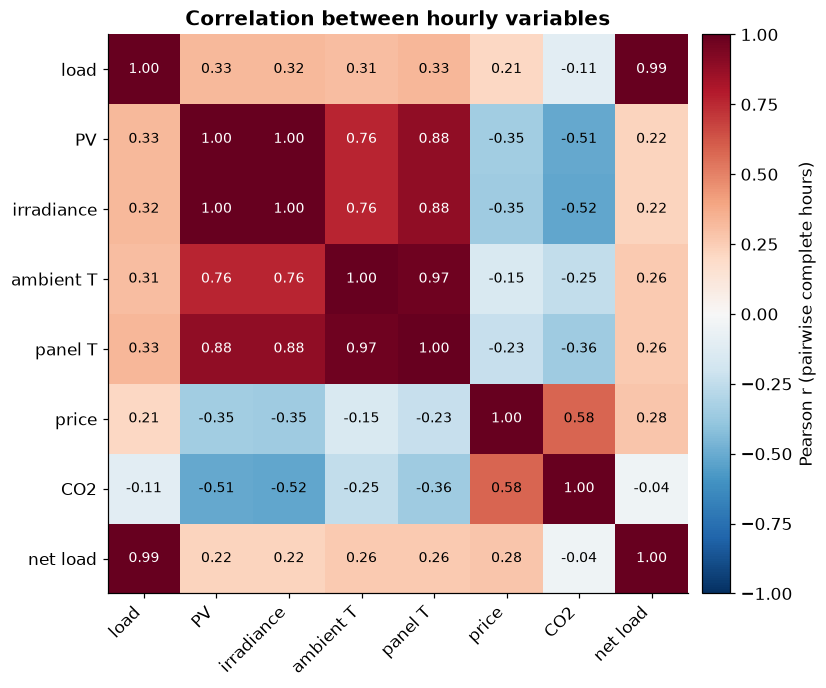

In [17]:
corr_cols = {"load_kw": "load", "pv_kw": "PV", "irr_w_m2": "irradiance", "t_amb_c": "ambient T",
             "t_panel_c": "panel T", "price": "price", "co2": "CO2", "net_load_kw": "net load"}
C = H[list(corr_cols)].corr()
fig, ax = plt.subplots(figsize=(8.2, 6.6))
im = heat(ax, C.to_numpy(), CMAP_DIV, "Pearson r (pairwise complete hours)", vmin=-1, vmax=1)
ax.set_xticks(range(len(C)), labels=corr_cols.values(), rotation=45, ha="right")
ax.set_yticks(range(len(C)), labels=corr_cols.values())
for i in range(len(C)):
    for j in range(len(C)):
        ax.text(j, i, f"{C.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(C.iloc[i, j]) > 0.6 else "black")
ax.set_title("Correlation between hourly variables")
pairs = C.where(np.triu(np.ones(C.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
print("Strongest pairs:", [f"{a}-{b}: {v:.2f}" for (a, b), v in pairs.head(6).items()])
print(f"price vs CO2: r = {C.loc['price', 'co2']:.2f}; load vs ambient temperature: r = {C.loc['load_kw', 't_amb_c']:.2f}")

**Takeaways**
- Price and CO2 are related but not the same signal: r = 0.58. Both matter, which supports the 0.7/0.3 blend.
- Load is only weakly tied to weather: r = 0.31 with ambient temperature. Net load is almost the same as load (r = 0.99), because PV is so small.

## 6. Battery opportunity

Composite signal v = 0.7 * CO2 / mean(CO2) + 0.3 * price / mean(price), mirroring the scoring weights. Only complete days (all 24 hours with both price and CO2) are used, so each day has a clean minimum and maximum. A round trip pays off when max(v)/min(v) exceeds 1 / efficiency.

Complete days used: 281 of 365 calendar days in the window
Top charge hours: {14: 117, 15: 35, 13: 22}
Top discharge hours: {21: 84, 20: 50, 19: 38}


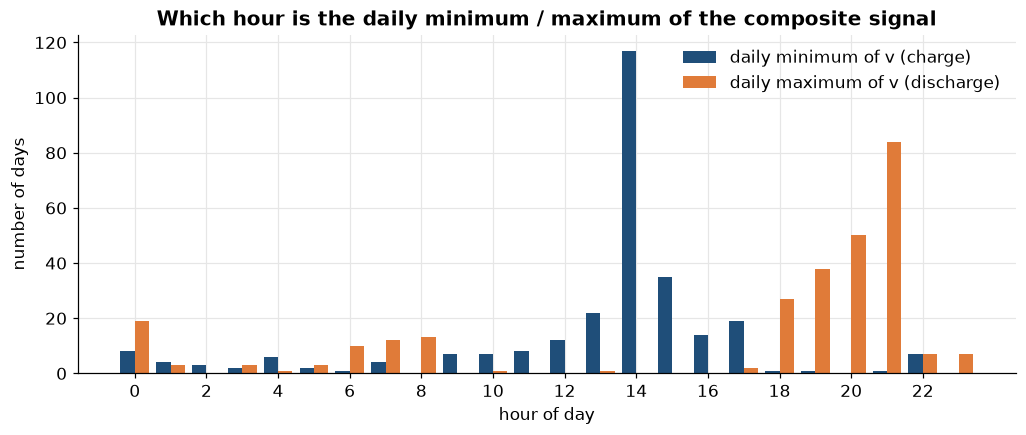

In [18]:
H["v"] = 0.7 * H.co2 / H.co2.mean() + 0.3 * H.price / H.price.mean()
day = H.index.normalize()
complete = H.v.notna().groupby(day).transform("sum") == 24
V = H.loc[complete, ["v"]]
vday = V.v.groupby(V.index.normalize())
daily = pd.DataFrame({"vmin": vday.min(), "vmax": vday.max(),
                      "hour_min": vday.idxmin().dt.hour, "hour_max": vday.idxmax().dt.hour})
daily["ratio"] = daily.vmax / daily.vmin
print(f"Complete days used: {len(daily)} of {H.index.normalize().nunique()} calendar days in the window")

fig, ax = plt.subplots(figsize=(11, 4))
hrs = np.arange(24)
cmin = daily.hour_min.value_counts().reindex(hrs, fill_value=0)
cmax = daily.hour_max.value_counts().reindex(hrs, fill_value=0)
ax.bar(hrs - 0.2, cmin, width=0.4, color=C_MAIN, label="daily minimum of v (charge)")
ax.bar(hrs + 0.2, cmax, width=0.4, color=C_ACC, label="daily maximum of v (discharge)")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("hour of day")
ax.set_ylabel("number of days")
ax.legend(frameon=False)
ax.set_title("Which hour is the daily minimum / maximum of the composite signal")
print("Top charge hours:", cmin.sort_values(ascending=False).head(3).to_dict())
print("Top discharge hours:", cmax.sort_values(ascending=False).head(3).to_dict())

**Takeaways**
- The composite signal's daily minimum (best time to charge) falls at 14 h on 117 of 281 complete days, and at 13-15 h on 174 days.
- The daily maximum (best time to discharge) falls at 21 h on 84 days, and at 19-21 h on 172 days.

Median daily ratio 2.658; days above break-even: 281 of 281 (100.0%)


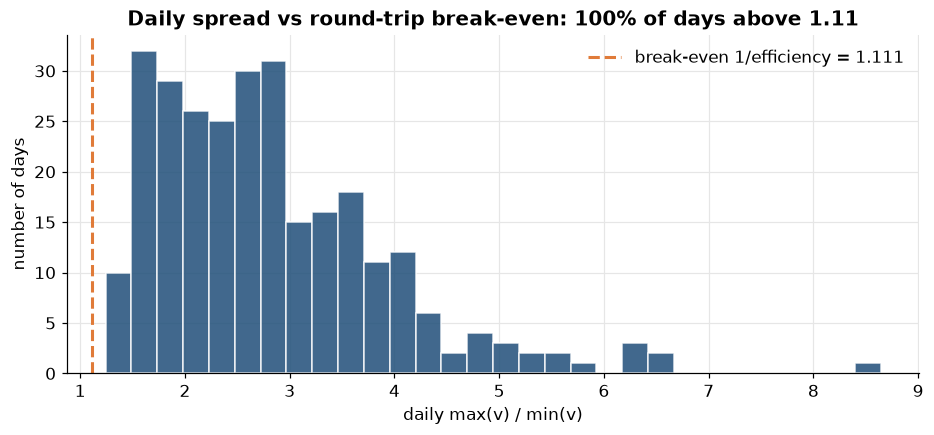

In [19]:
BE = 1 / SPEC["efficiency"]
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(daily.ratio, bins=30, color=C_MAIN, alpha=0.85, edgecolor="white")
ax.axvline(x=BE, color=C_ACC, ls="--", lw=2, label=f"break-even 1/efficiency = {BE:.3f}")
ax.set_xlabel("daily max(v) / min(v)")
ax.set_ylabel("number of days")
ax.legend(frameon=False)
share = (daily.ratio > BE).mean()
ax.set_title(f"Daily spread vs round-trip break-even: {share:.0%} of days above {BE:.2f}")
print(f"Median daily ratio {daily.ratio.median():.3f}; days above break-even: {int((daily.ratio > BE).sum())} "
      f"of {len(daily)} ({share:.1%})")

**Takeaways**
- The median daily max(v)/min(v) is 2.66, and all 281 complete days clear the 1.11 break-even. On this signal the spread is profitable every day, so the battery should do a full cycle whenever it can.
- A full 2000 kWh charge at 500 kW takes 4 h, which is longer than the 3-hour midday trough (13-15 h). Charging therefore has to spread over neighbouring hours, and the choice of which hours to use is what needs tuning.

In [20]:
# Battery in proportion to campus consumption (complete days only)
# Several hours per day, not one: mean v of the 4 cheapest and 4 most expensive hours of each complete day
rk = V.assign(day=V.index.normalize(), hour=V.index.hour).sort_values(["day", "v"])
rk["from_low"] = rk.groupby("day").cumcount()
rk["from_high"] = rk.groupby("day").cumcount(ascending=False)
low4 = rk[rk.from_low < 4].groupby("day").v.mean()
high4 = rk[rk.from_high < 4].groupby("day").v.mean()
span = rk[rk.from_low < 4].groupby("day")["hour"].agg(["min", "max"]).eval("max - min")
print(f"Per day, mean v of the 4 cheapest hours: median {low4.median():.3f}; of the 4 most expensive: "
      f"median {high4.median():.3f}; median ratio {(high4 / low4).median():.2f}")
print(f"Hours between the first and last of the 4 cheapest: median {span.median():.0f} h, 90th percentile {span.quantile(0.9):.0f} h")
kwh_day = H.load_kw.groupby(H.index.normalize()).agg(["count", "sum"])
kwh_day = kwh_day.loc[kwh_day["count"] == 24, "sum"]  # kW x 1 h = kWh
mean_day = kwh_day.mean()
mean_load = H.load_kw.mean()
print(f"Battery: {SPEC['capacity_kwh']} kWh, {SPEC['power_kw']} kW, efficiency {SPEC['efficiency']}")
print(f"Mean daily consumption: {mean_day:,.0f} kWh over {len(kwh_day)} complete days")
print(f"Battery energy = {SPEC['capacity_kwh'] / mean_day:.1%} of a mean day's consumption")
print(f"Mean load: {mean_load:.0f} kW; battery power = {SPEC['power_kw'] / mean_load:.1%} of mean load")

Per day, mean v of the 4 cheapest hours: median 0.562; of the 4 most expensive: median 1.410; median ratio 2.32
Hours between the first and last of the 4 cheapest: median 3 h, 90th percentile 11 h
Battery: 2000 kWh, 500 kW, efficiency 0.9
Mean daily consumption: 26,821 kWh over 254 complete days
Battery energy = 7.5% of a mean day's consumption
Mean load: 1118 kW; battery power = 44.7% of mean load


**Takeaways**
- The battery holds 7.5% of a mean day's consumption (26,821 kWh over 254 complete days), and its 500 kW is 44.7% of the mean load of 1118 kW. It can move grid imports for hours at a time, but it cannot cover the campus for a day.
- Per day, the mean v of the 4 cheapest hours is 0.562, against 1.410 for the 4 most expensive (median ratio 2.32). The four cheapest hours are usually consecutive (median span 3 h, 90th percentile 11 h), so the charge should spread over the neighbouring hours around the trough.

## 7. Key findings and next steps

### Key findings

1. **Load and PV.** Mean load is 1118 kW and mean PV is 26.5 kW (2.4% of load). Net load never goes negative (0 of 5975 hours), so there is no free solar to store; any charging comes from the grid.
2. **Price and CO2 share a daily shape.** Both trough around 13-14 h and peak at 21 h. Price varies 3.07x across the day and CO2 varies 2.11x.
3. **The spread is profitable every day.** The composite v has a median daily max/min of 2.66, and all 281 complete days exceed the 1.11 break-even.
4. **Charge and discharge over several hours.** The spread is large every day, so the battery should cycle daily. A full 2 MWh charge at 500 kW takes 4 h, and the four cheapest hours are usually consecutive (median span 3 h). The choice of hours around 13-15 h is what needs tuning.
5. **Battery size against the campus.** 2 MWh is 7.5% of a mean day's consumption and 500 kW is 44.7% of mean load. The battery is a daily cycling resource: its value depends on the hours it uses, not on its size.
6. **Load regime changes.** Weekday daytime load (median 1362 kW) and June-July (means 1325-1449 kW) are far above weekend or August levels (756 kW and 854 kW). A policy tuned to one regime may misbehave in another.
7. **Data gaps shape validation.** Every file is missing the 7-day test windows, November 2025 has no load or PV, the inverter stops on 2026-08-16, and the meter has zero-reading outages.

### Next steps (in priority order)

1. **Fix the data pipeline first.** Put the zero-to-missing rule (runs listed in section 3), the 6-of-12 hourly rule, the outage gaps (section 1) and the inverter cutoff at 2026-08-16 22:00 in one shared loader.
2. **Build a simple price/CO2 baseline.** Charge over about 4 consecutive hours around the midday trough and discharge over the evening peak, sized to 500 kW and 2 MWh with SOC limits. Score it on the hourly table with the 70/30 formula before anything learned.
3. **Tune which hours to use.** Test start times for the 4-hour charge (roughly 11-15 h) and discharge windows (roughly 19-21 h) on the composite v, rather than fixing a single hour.
4. **Skip PV forecasting.** Consider load forecasting only if the baseline error shows that load drives it; net load tracks load (r = 0.99).
5. **Validate on 12 local weeks.** Hold out the 7 days immediately before each month's hidden-test week (the last 7 available days of each month), giving 12 weekly folds. Score each with the 70/30 formula. November has no load or PV in the 5-min files, so its week can only be scored if load is imputed.
6. **Confirm the August drop with the data owner.** Check whether 854 kW in August reflects a shutdown or a metering change before using August as validation.
7. **Build for zero infractions.** The local simulator in `starter_kit/environment.py` charges 0.2 points per infraction (0.002 on a fraction scale, times 100), while `docs/ENUNCIAT.md` states 1.00 point. Until the official value is confirmed, build the agent to produce zero infractions rather than trading them off.